# Estimação de Parâmetros e Testes de Hipótese

Material de apoio para a aula **PNV-3421 · Processos Estocásticos** (Prof. Dr. André Bergsten Mendes), com simulações em Python para cada conceito apresentado nos slides: estimação pontual, Teorema do Limite Central, intervalos de confiança (variância conhecida e desconhecida) e testes de hipótese sobre a média.

**Roteiro:**
1. Fundamentos da inferência
2. Estimação pontual e TLC
3. Intervalos de confiança
4. Testes de hipótese
5. Síntese
6. Exercícios propostos


In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (10, 4)


## 1. Fundamentos da Inferência

Na estatística descritiva resumimos os dados observados ($\bar{x}$, $s$). Na **inferência**, usamos esse resumo para dizer algo sobre o processo estocástico que gerou os dados: **estimar** seus parâmetros ($\mu$, $\sigma$) e **testar** afirmações sobre eles.

Vamos simular um "processo estocástico" com parâmetros conhecidos (o que normalmente não temos na prática) para poder comparar nossas estimativas com a verdade — essa é a ideia central deste notebook: gerar dados de uma população conhecida e verificar se os métodos de estimação e teste recuperam corretamente os parâmetros verdadeiros.


In [2]:
# "Processo estocástico" de referência: tempo entre chegadas de peças a uma estação (exponencial)
mu_verdadeiro = 10.0     # média verdadeira do processo (desconhecida na prática)
sigma_verdadeiro = 10.0  # para a exponencial, sigma = mu

populacao = stats.expon(scale=mu_verdadeiro)
amostra_exemplo = populacao.rvs(size=30, random_state=rng)

print(f"Média amostral (x̄):   {amostra_exemplo.mean():.3f}")
print(f"Desvio padrão (s):     {amostra_exemplo.std(ddof=1):.3f}")
print(f"Parâmetro real (μ):    {mu_verdadeiro}")


Média amostral (x̄):   9.331
Desvio padrão (s):     8.434
Parâmetro real (μ):    10.0


## 2. Estimação Pontual e TLC

### 2.1 O estimador pontual da média

$$\bar{X} = \frac{1}{n}\sum_{i=1}^n X_i$$

Um bom estimador é:
- **Não-viesado**: $E[\bar{X}] = \mu$
- **Consistente**: a variância do estimador cai com $n$
- **Eficiente**: tem a menor variância possível entre os não-viesados

Vamos verificar as duas primeiras propriedades por simulação: repetimos o experimento de coletar uma amostra milhares de vezes e olhamos a distribuição das médias amostrais resultantes.


In [3]:
# Gera n_simulacoes amostras de tamanho n e retorna o vetor de médias amostrais
def simular_medias_amostrais(distribuicao, n, n_simulacoes=5000, rng=rng):
    amostras = distribuicao.rvs(size=(n_simulacoes, n), random_state=rng)
    return amostras.mean(axis=1)

medias_n30 = simular_medias_amostrais(populacao, n=30)

print(f"Média das médias amostrais (deveria ≈ μ={mu_verdadeiro}): {medias_n30.mean():.3f}  -> não-viesado")
print(f"Desvio padrão das médias amostrais (erro padrão empírico): {medias_n30.std(ddof=1):.3f}")
print(f"Erro padrão teórico σ/√n = {sigma_verdadeiro/np.sqrt(30):.3f}")


Média das médias amostrais (deveria ≈ μ=10.0): 10.017  -> não-viesado
Desvio padrão das médias amostrais (erro padrão empírico): 1.820
Erro padrão teórico σ/√n = 1.826


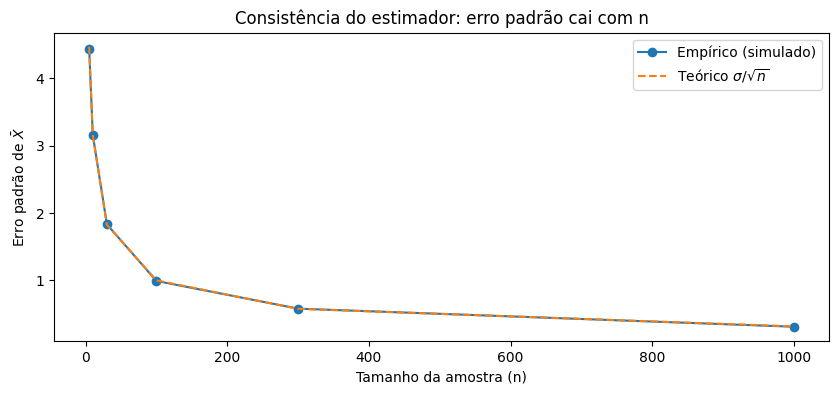

In [4]:
# Consistência: a variância do estimador cai conforme n cresce
tamanhos = [5, 10, 30, 100, 300, 1000]
erros_padrao_empiricos = [simular_medias_amostrais(populacao, n).std(ddof=1) for n in tamanhos]
erros_padrao_teoricos = [sigma_verdadeiro / np.sqrt(n) for n in tamanhos]

fig, ax = plt.subplots()
ax.plot(tamanhos, erros_padrao_empiricos, "o-", label="Empírico (simulado)")
ax.plot(tamanhos, erros_padrao_teoricos, "--", label=r"Teórico $\sigma/\sqrt{n}$")
ax.set_xlabel("Tamanho da amostra (n)")
ax.set_ylabel(r"Erro padrão de $\bar{X}$")
ax.set_title("Consistência do estimador: erro padrão cai com n")
ax.legend()
plt.show()


### 2.2 Teorema do Limite Central (TLC)

$$\bar{X} \sim N\left(\mu, \frac{\sigma^2}{n}\right), \quad n \text{ grande}$$

O TLC vale **seja qual for a distribuição de X**. Vamos reproduzir o exemplo clássico do slide: a distribuição da média de $n$ lançamentos de um dado (uniforme discreto entre 1 e 6) — uma distribuição bem distante de uma normal — converge rapidamente para o formato de sino conforme $n$ cresce.


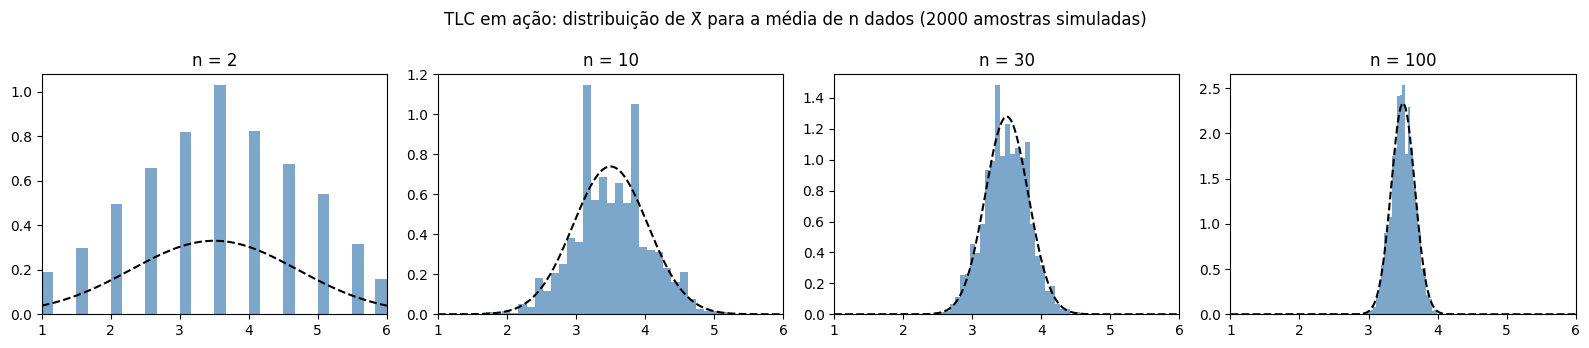

In [5]:
def media_de_dados(n, n_simulacoes=2000, rng=rng):
    lancamentos = rng.integers(1, 7, size=(n_simulacoes, n))
    return lancamentos.mean(axis=1)

tamanhos_tlc = [2, 10, 30, 100]
mu_dado = 3.5
sigma_dado = np.sqrt(np.mean((np.arange(1, 7) - mu_dado) ** 2))

fig, axes = plt.subplots(1, len(tamanhos_tlc), figsize=(16, 3.5), sharex=True)
for ax, n in zip(axes, tamanhos_tlc):
    medias = media_de_dados(n)
    ax.hist(medias, bins=30, density=True, alpha=0.7, color="steelblue")
    x = np.linspace(1, 6, 200)
    ax.plot(x, stats.norm(mu_dado, sigma_dado / np.sqrt(n)).pdf(x), "k--", lw=1.5)
    ax.set_title(f"n = {n}")
    ax.set_xlim(1, 6)
fig.suptitle("TLC em ação: distribuição de X̄ para a média de n dados (2000 amostras simuladas)")
plt.tight_layout()
plt.show()


### 2.3 Erro padrão da média

$$\sigma_{\bar{X}} = \frac{\sigma}{\sqrt{n}}$$

Não confundir: o **desvio padrão** ($\sigma$) mede a dispersão de uma observação individual; o **erro padrão** ($\sigma/\sqrt{n}$) mede a dispersão da *média* de $n$ observações — e é sempre menor que $\sigma$.


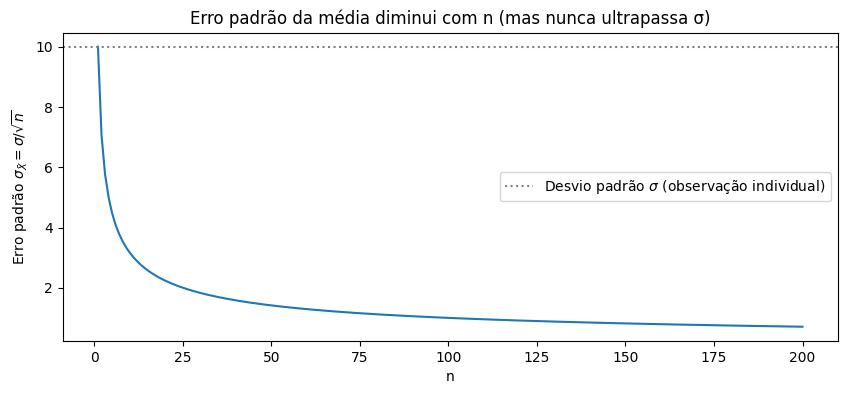

In [6]:
ns = np.arange(1, 201)
erro_padrao = sigma_verdadeiro / np.sqrt(ns)

fig, ax = plt.subplots()
ax.plot(ns, erro_padrao)
ax.axhline(sigma_verdadeiro, color="gray", linestyle=":", label=r"Desvio padrão $\sigma$ (observação individual)")
ax.set_xlabel("n")
ax.set_ylabel(r"Erro padrão $\sigma_{\bar{X}} = \sigma/\sqrt{n}$")
ax.set_title("Erro padrão da média diminui com n (mas nunca ultrapassa σ)")
ax.legend()
plt.show()


## 3. Intervalos de Confiança

### 3.1 Variância conhecida

$$\left[\bar{X} - z\frac{\sigma}{\sqrt{n}} \ ;\ \bar{X} + z\frac{\sigma}{\sqrt{n}}\right]$$

**Exemplo 1 (slide) — Tempo de estudo populacional.** $X \sim N(\mu, 2{,}6^2)$, $n=25$, $\bar{x}=10{,}5$ anos, confiança de 90%. Esperado: $[9{,}64\ ;\ 11{,}36]$ anos.


In [7]:
# Intervalo de confiança para a média com variância populacional conhecida
def ic_variancia_conhecida(xbar, sigma, n, confianca):
    z = stats.norm.ppf(0.5 + confianca / 2)
    erro = z * sigma / np.sqrt(n)
    return xbar - erro, xbar + erro, z, erro

li, ls, z, eps = ic_variancia_conhecida(xbar=10.5, sigma=2.6, n=25, confianca=0.90)
print(f"z = {z:.3f},  erro amostral ε = {eps:.3f}")
print(f"IC 90% = [{li:.2f} ; {ls:.2f}] anos   (esperado: [9.64 ; 11.36])")


z = 1.645,  erro amostral ε = 0.855
IC 90% = [9.64 ; 11.36] anos   (esperado: [9.64 ; 11.36])


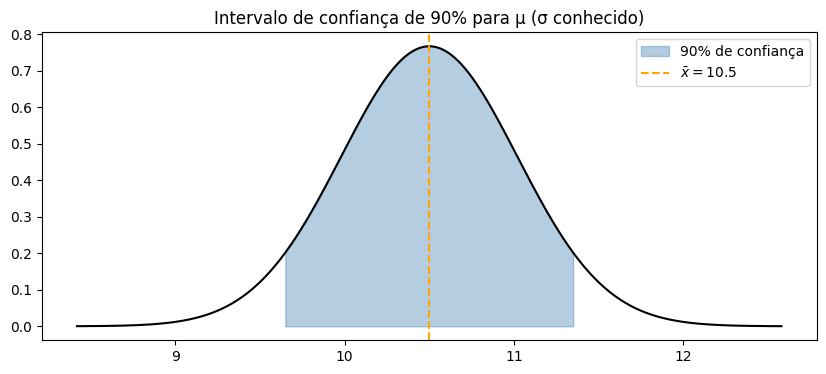

In [8]:
# Visualização: distribuição de X̄ sob H, com a área central de 90% destacada
xbar, sigma, n = 10.5, 2.6, 25
x = np.linspace(xbar - 4 * sigma / np.sqrt(n), xbar + 4 * sigma / np.sqrt(n), 400)
y = stats.norm(xbar, sigma / np.sqrt(n)).pdf(x)

fig, ax = plt.subplots()
ax.plot(x, y, color="black")
mascara = (x >= li) & (x <= ls)
ax.fill_between(x[mascara], y[mascara], color="steelblue", alpha=0.4, label="90% de confiança")
ax.axvline(xbar, color="orange", linestyle="--", label=r"$\bar{x}=10.5$")
ax.set_title("Intervalo de confiança de 90% para μ (σ conhecido)")
ax.legend()
plt.show()


### 3.2 Dimensionamento da amostra

$$n = \left(\frac{z}{\varepsilon}\right)^2 \sigma^2$$

**Exemplo 2 (slide) — Baterias.** $\sigma = 50$h, erro desejado $\varepsilon = 20$h, confiança 90%.

> **Nota:** o slide afirma que o resultado é $n \approx 207$, mas aplicando a própria fórmula do slide aos números dados ($z=1{,}645$, $\sigma=50$, $\varepsilon=20$) o resultado correto é $n\approx17$ — o slide parece conter um erro de conta. Calculamos abaixo com a fórmula correta e conferimos a conta manualmente.


In [9]:
# Tamanho de amostra necessário para um erro amostral máximo dado, com confiança γ
def tamanho_amostra(sigma, erro, confianca):
    z = stats.norm.ppf(0.5 + confianca / 2)
    n = (z / erro) ** 2 * sigma ** 2
    return int(np.ceil(n))

n_baterias = tamanho_amostra(sigma=50, erro=20, confianca=0.90)
print(f"n = {n_baterias} baterias")

# Conferindo a conta manualmente: n = (z/ε)² σ²
z = stats.norm.ppf(0.95)
conta_manual = (z / 20) ** 2 * 50 ** 2
print(f"Conferência manual: (z/ε)²σ² = ({z:.3f}/20)² × 50² = {conta_manual:.2f}  (o slide afirma 206,25 — discrepância no material original)")


n = 17 baterias
Conferência manual: (z/ε)²σ² = (1.645/20)² × 50² = 16.91  (o slide afirma 206,25 — discrepância no material original)


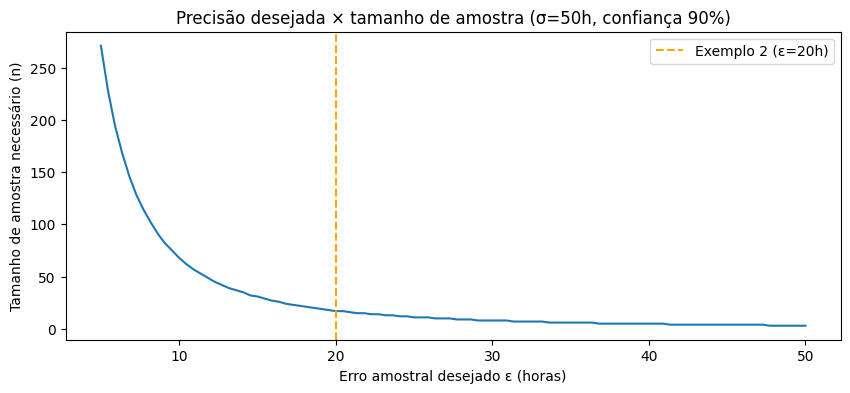

In [10]:
# Trade-off: quanto menor o erro desejado, maior a amostra necessária
erros = np.linspace(5, 50, 100)
ns_necessarios = [tamanho_amostra(sigma=50, erro=e, confianca=0.90) for e in erros]

fig, ax = plt.subplots()
ax.plot(erros, ns_necessarios)
ax.axvline(20, color="orange", linestyle="--", label="Exemplo 2 (ε=20h)")
ax.set_xlabel("Erro amostral desejado ε (horas)")
ax.set_ylabel("Tamanho de amostra necessário (n)")
ax.set_title("Precisão desejada × tamanho de amostra (σ=50h, confiança 90%)")
ax.legend()
plt.show()


### 3.3 Variância desconhecida — distribuição t de Student

Na prática, $\sigma^2$ quase sempre é desconhecida e é substituída pela estimativa amostral $s^2$ (com correção de Bessel, $n-1$ no denominador). Isso introduz incerteza extra, capturada pela distribuição **t de Student**, que tem caudas mais pesadas que a normal — e se aproxima dela conforme os graus de liberdade aumentam.


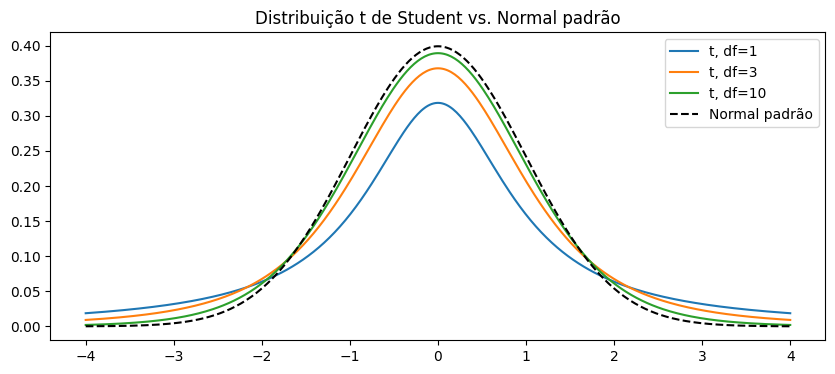

In [11]:
x = np.linspace(-4, 4, 400)
fig, ax = plt.subplots()
for df in [1, 3, 10]:
    ax.plot(x, stats.t(df).pdf(x), label=f"t, df={df}")
ax.plot(x, stats.norm.pdf(x), "k--", label="Normal padrão")
ax.set_title("Distribuição t de Student vs. Normal padrão")
ax.legend()
plt.show()


**Exemplo 3 (slide) — Consumo de combustível.** $n=10$, $\bar{x}=8$ km/l, $s=4$ km/l, IC de 95%. Esperado: $[5{,}14\ ;\ 10{,}86]$ km/l.


In [12]:
# Intervalo de confiança para a média com variância populacional desconhecida (usa t de Student)
def ic_variancia_desconhecida(xbar, s, n, confianca):
    t_critico = stats.t.ppf(0.5 + confianca / 2, df=n - 1)
    erro = t_critico * s / np.sqrt(n)
    return xbar - erro, xbar + erro, t_critico, erro

li, ls, t_crit, eps = ic_variancia_desconhecida(xbar=8, s=4, n=10, confianca=0.95)
print(f"t_9 (95%) = {t_crit:.3f}")
print(f"IC 95% = [{li:.2f} ; {ls:.2f}] km/l   (esperado: [5.14 ; 10.86])")


t_9 (95%) = 2.262
IC 95% = [5.14 ; 10.86] km/l   (esperado: [5.14 ; 10.86])


### 3.4 Z ou t? Verificação por simulação

A tabela de síntese do slide diz: com $\sigma$ conhecido usamos $Z$; com $\sigma$ desconhecido e amostra pequena de uma população normal, usamos $t$. Vamos verificar empiricamente por que usar $Z$ no lugar de $t$ quando $n$ é pequeno é um erro: simulamos milhares de amostras de tamanho $n=10$ de uma população normal, construímos o IC de 95% de duas formas (com $z$ e com $t$, sempre estimando $s$ a partir da amostra) e comparamos a fração de intervalos que realmente contêm $\mu$ — a **cobertura empírica**.


In [13]:
def cobertura_empirica(n, confianca=0.95, n_simulacoes=5000, mu=50, sigma=10, rng=rng):
    amostras = rng.normal(mu, sigma, size=(n_simulacoes, n))
    xbars = amostras.mean(axis=1)
    s = amostras.std(axis=1, ddof=1)

    z = stats.norm.ppf(0.5 + confianca / 2)
    cobre_z = np.abs(xbars - mu) <= z * s / np.sqrt(n)

    t_crit = stats.t.ppf(0.5 + confianca / 2, df=n - 1)
    cobre_t = np.abs(xbars - mu) <= t_crit * s / np.sqrt(n)

    return cobre_z.mean(), cobre_t.mean()

for n in [5, 10, 30, 100]:
    cob_z, cob_t = cobertura_empirica(n)
    print(f"n={n:>4}:  cobertura usando Z = {cob_z:.3f}   |   cobertura usando t = {cob_t:.3f}   (nominal: 0.950)")


n=   5:  cobertura usando Z = 0.878   |   cobertura usando t = 0.953   (nominal: 0.950)
n=  10:  cobertura usando Z = 0.909   |   cobertura usando t = 0.940   (nominal: 0.950)
n=  30:  cobertura usando Z = 0.943   |   cobertura usando t = 0.951   (nominal: 0.950)
n= 100:  cobertura usando Z = 0.949   |   cobertura usando t = 0.953   (nominal: 0.950)


Repare: para $n$ pequeno, usar $Z$ (em vez de $t$) produz uma cobertura **abaixo** dos 95% nominais — os intervalos são estreitos demais porque não compensam a incerteza extra de estimar $\sigma$ por $s$. Conforme $n$ cresce, as duas abordagens convergem, confirmando a tabela do slide.


## 4. Testes de Hipótese

### 4.1 Região crítica, erro tipo I e erro tipo II

**Exemplo 4 (slide) — Consumo de combustível.** Fabricante afirma $\mu=9$ km/l. $H: \mu=9$ vs $A: \mu\neq9$. $n=100$, $\sigma=10$ (conhecido). Região crítica dada: $R_c = \{\bar{X}\le7{,}5 \text{ ou } \bar{X}\ge10{,}5\}$.

Vamos calcular $\alpha = P(\text{Erro I})$ sob $H$ verdadeira ($\mu=9$) e $\beta = P(\text{Erro II})$ supondo que a média real seja $\mu=8$.


In [14]:
mu0, sigma, n = 9, 10, 100
erro_padrao = sigma / np.sqrt(n)
k1, k2 = 7.5, 10.5

dist_sob_H = stats.norm(mu0, erro_padrao)
alpha = dist_sob_H.cdf(k1) + dist_sob_H.sf(k2)
print(f"α = P(erro tipo I) = {alpha:.4f}  ({alpha*100:.2f}%)   (esperado: 13.36%)")

mu_real = 8
dist_sob_mu_real = stats.norm(mu_real, erro_padrao)
beta = dist_sob_mu_real.cdf(k2) - dist_sob_mu_real.cdf(k1)
print(f"β = P(erro tipo II | μ={mu_real}) = {beta:.4f}  ({beta*100:.2f}%)   (esperado: 68.53%)")


α = P(erro tipo I) = 0.1336  (13.36%)   (esperado: 13.36%)
β = P(erro tipo II | μ=8) = 0.6853  (68.53%)   (esperado: 68.53%)


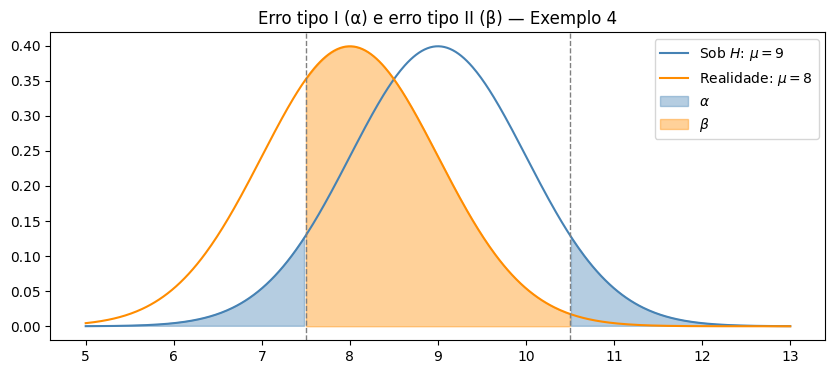

In [15]:
# Visualização clássica: distribuição sob H0 (α) e sob a alternativa real (β)
x = np.linspace(5, 13, 500)
fig, ax = plt.subplots()
ax.plot(x, dist_sob_H.pdf(x), label=r"Sob $H$: $\mu=9$", color="steelblue")
ax.plot(x, dist_sob_mu_real.pdf(x), label=fr"Realidade: $\mu={mu_real}$", color="darkorange")

mascara_alpha = (x <= k1) | (x >= k2)
ax.fill_between(x, dist_sob_H.pdf(x), where=mascara_alpha, color="steelblue", alpha=0.4, label=r"$\alpha$")

mascara_beta = (x > k1) & (x < k2)
ax.fill_between(x, dist_sob_mu_real.pdf(x), where=mascara_beta, color="darkorange", alpha=0.4, label=r"$\beta$")

for k in (k1, k2):
    ax.axvline(k, color="gray", linestyle="--", lw=1)
ax.set_title("Erro tipo I (α) e erro tipo II (β) — Exemplo 4")
ax.legend()
plt.show()


### 4.2 Confirmando α por simulação de Monte Carlo

Em vez de calcular $\alpha$ analiticamente, podemos estimá-lo simulando: gerar milhares de amostras **sob $H$ verdadeira** ($\mu=9$), aplicar a regra de decisão e contar a fração de vezes que rejeitamos $H$ por engano. Deve convergir para o $\alpha$ teórico calculado acima.


In [16]:
n_simulacoes = 20000
amostras = rng.normal(mu0, sigma, size=(n_simulacoes, n))
xbars = amostras.mean(axis=1)
rejeicoes = (xbars <= k1) | (xbars >= k2)

alpha_simulado = rejeicoes.mean()
print(f"α teórico:   {alpha:.4f}")
print(f"α simulado:  {alpha_simulado:.4f}  ({n_simulacoes} amostras sob H verdadeira)")


α teórico:   0.1336
α simulado:  0.1346  (20000 amostras sob H verdadeira)


### 4.3 Teste unilateral

**Exemplo 5 (slide) — Fila de votação.** $H: \mu=24$ vs $A: \mu<24$. $X$ aproximadamente normal, $\sigma=4{,}6$ min, $n=12$, $\alpha=0{,}05$. Região crítica: $R_c=\{\bar{X}\le k\}$, com $k$ tal que $P(\text{Erro I})=\alpha$.


In [17]:
def regiao_critica_unilateral(mu0, sigma, n, alpha, cauda="esquerda"):
    erro_padrao = sigma / np.sqrt(n)
    z = stats.norm.ppf(alpha)  # negativo
    if cauda == "esquerda":
        k = mu0 + z * erro_padrao
    else:
        k = mu0 - z * erro_padrao
    return k

k = regiao_critica_unilateral(mu0=24, sigma=4.6, n=12, alpha=0.05, cauda="esquerda")
print(f"k = {k:.2f}   (esperado: 21.8)")

xbar_observado = 21.7
decisao = "rejeitamos H" if xbar_observado <= k else "não rejeitamos H"
print(f"X̄ observado = {xbar_observado}  ->  {decisao}")


k = 21.82   (esperado: 21.8)
X̄ observado = 21.7  ->  rejeitamos H


### 4.4 Nível descritivo (p-valor)

Em vez de fixar $\alpha$ antes de ver os dados, o **p-valor** mede a força da evidência amostral contra $H$: quanto menor, mais evidência contra $H$. Regra: $P \le \alpha \Rightarrow$ rejeitamos $H$.

**Exemplo 6 (slide) —** $H: \mu=10$ vs $A: \mu<10$, $\sigma$ desconhecido, $n=10$, $\bar{x}=4$, $s=10$ (usa-se $t_{9}$). Esperado: $P \approx 0{,}045$.


In [18]:
# Testa H: mu = mu0 contra a alternativa indicada em `tipo`
# ("bilateral", "menor" para mu<mu0, ou "maior" para mu>mu0).
# Retorna um dicionário com a estatística de teste, o p-valor e a distribuição usada.
def teste_hipotese_media(xbar, mu0, s_ou_sigma, n, tipo="bilateral", sigma_conhecido=False):
    erro_padrao = s_ou_sigma / np.sqrt(n)
    estatistica = (xbar - mu0) / erro_padrao

    if sigma_conhecido:
        dist = stats.norm()
        nome_dist = "Z (normal)"
    else:
        dist = stats.t(df=n - 1)
        nome_dist = f"t com {n-1} graus de liberdade"

    if tipo == "bilateral":
        p_valor = 2 * dist.sf(abs(estatistica))
    elif tipo == "menor":
        p_valor = dist.cdf(estatistica)
    elif tipo == "maior":
        p_valor = dist.sf(estatistica)
    else:
        raise ValueError("tipo deve ser 'bilateral', 'menor' ou 'maior'")

    return {"estatistica": estatistica, "p_valor": p_valor, "distribuicao": nome_dist}

resultado = teste_hipotese_media(xbar=4, mu0=10, s_ou_sigma=10, n=10, tipo="menor", sigma_conhecido=False)
print(f"Estatística de teste ({resultado['distribuicao']}): {resultado['estatistica']:.3f}")
print(f"p-valor = {resultado['p_valor']:.4f}   (esperado: ≈0.045)")

alpha = 0.05
decisao = "rejeitamos H" if resultado["p_valor"] <= alpha else "não rejeitamos H"
print(f"Com α={alpha}: {decisao}")


Estatística de teste (t com 9 graus de liberdade): -1.897
p-valor = 0.0451   (esperado: ≈0.045)
Com α=0.05: rejeitamos H


## 5. Síntese

| | Estimação | Teste de Hipótese |
|---|---|---|
| **Pergunta** | Qual é o valor provável de μ? | Os dados sustentam uma afirmação específica sobre μ? |
| **Resultado** | Um valor (pontual) ou intervalo | Uma decisão: rejeitar ou não rejeitar H |
| **Ferramenta-chave** | Erro padrão, z ou t | Região crítica, α, β, p-valor |

Os dois lados são conectados: um intervalo de confiança de $(1-\alpha)$ para $\mu$ contém exatamente os valores de $\mu_0$ que **não seriam rejeitados** por um teste bilateral com significância $\alpha$. Vamos verificar isso numericamente com o Exemplo 3 (consumo de combustível, $n=10$, $\bar{x}=8$, $s=4$).


In [19]:
xbar, s, n = 8, 4, 10
confianca = 0.95
alpha = 1 - confianca

li, ls, _, _ = ic_variancia_desconhecida(xbar, s, n, confianca)
print(f"IC 95% para μ: [{li:.2f} ; {ls:.2f}]")

for mu0_teste in [4, li, 6, 8, ls, 12]:
    r = teste_hipotese_media(xbar, mu0_teste, s, n, tipo="bilateral", sigma_conhecido=False)
    dentro_do_ic = li <= mu0_teste <= ls
    rejeita = r["p_valor"] <= alpha
    print(f"μ0={mu0_teste:6.2f}  |  dentro do IC: {str(dentro_do_ic):5}  |  rejeita H (α=5%): {rejeita}")


IC 95% para μ: [5.14 ; 10.86]
μ0=  4.00  |  dentro do IC: False  |  rejeita H (α=5%): True
μ0=  5.14  |  dentro do IC: True   |  rejeita H (α=5%): True
μ0=  6.00  |  dentro do IC: True   |  rejeita H (α=5%): False
μ0=  8.00  |  dentro do IC: True   |  rejeita H (α=5%): False
μ0= 10.86  |  dentro do IC: True   |  rejeita H (α=5%): True
μ0= 12.00  |  dentro do IC: False  |  rejeita H (α=5%): True


## 6. Exercícios Propostos

Resolução dos exercícios da última página do material, usando as funções construídas acima (`ic_variancia_conhecida`, `tamanho_amostra`, `teste_hipotese_media`).


### Exercício 1

Uma variável aleatória tem distribuição normal e desvio padrão igual a 12. Estamos testando se sua média é igual ou diferente de 20 e coletamos uma amostra de 100 valores dessa variável, obtendo uma média amostral de 17,4.

**(a)** Formule as hipóteses.
**(b)** Obtenha a região crítica e dê sua conclusão do teste para $\alpha$ = 1%, 2%, 4%, 6% e 8%.
**(c)** Calcule o nível descritivo do teste e conclua para cada valor de $\alpha$ especificado em (b).


In [20]:
# (a) H: μ = 20  vs  A: μ ≠ 20   (bilateral)
sigma, n, xbar, mu0 = 12, 100, 17.4, 20
erro_padrao = sigma / np.sqrt(n)

# (b) Região crítica para cada α: Rc = {X̄ ≤ mu0 - z·ep} ∪ {X̄ ≥ mu0 + z·ep}
alphas = [0.01, 0.02, 0.04, 0.06, 0.08]
print("(b) Região crítica e decisão:")
for alpha in alphas:
    z = stats.norm.ppf(1 - alpha / 2)
    k1, k2 = mu0 - z * erro_padrao, mu0 + z * erro_padrao
    rejeita = (xbar <= k1) or (xbar >= k2)
    print(f"  α={alpha:.0%}: Rc = {{X̄≤{k1:.3f} ou X̄≥{k2:.3f}}}  ->  {'rejeitamos H' if rejeita else 'não rejeitamos H'}")

# (c) p-valor
resultado_ex1 = teste_hipotese_media(xbar, mu0, sigma, n, tipo="bilateral", sigma_conhecido=True)
p_valor_ex1 = resultado_ex1["p_valor"]
print(f"\n(c) Estatística Z = {resultado_ex1['estatistica']:.3f}   p-valor = {p_valor_ex1:.5f}")
for alpha in alphas:
    decisao = "rejeitamos H" if p_valor_ex1 <= alpha else "não rejeitamos H"
    print(f"  α={alpha:.0%}: P={p_valor_ex1:.5f} {'≤' if p_valor_ex1<=alpha else '>'} α  ->  {decisao}")


(b) Região crítica e decisão:
  α=1%: Rc = {X̄≤16.909 ou X̄≥23.091}  ->  não rejeitamos H
  α=2%: Rc = {X̄≤17.208 ou X̄≥22.792}  ->  não rejeitamos H
  α=4%: Rc = {X̄≤17.536 ou X̄≥22.464}  ->  rejeitamos H
  α=6%: Rc = {X̄≤17.743 ou X̄≥22.257}  ->  rejeitamos H
  α=8%: Rc = {X̄≤17.899 ou X̄≥22.101}  ->  rejeitamos H

(c) Estatística Z = -2.167   p-valor = 0.03026
  α=1%: P=0.03026 > α  ->  não rejeitamos H
  α=2%: P=0.03026 > α  ->  não rejeitamos H
  α=4%: P=0.03026 ≤ α  ->  rejeitamos H
  α=6%: P=0.03026 ≤ α  ->  rejeitamos H
  α=8%: P=0.03026 ≤ α  ->  rejeitamos H


### Exercício 2

Uma máquina deve produzir peças com diâmetro de 2 cm. Assumindo diâmetro ~ $N(\mu, 0{,}09)$ cm², uma amostra de 100 peças é coletada para testar se a máquina está bem regulada.

**(a)** Formule o problema como um teste de hipóteses.
**(b)** Obtenha a região crítica para $\alpha$ = 2%.
**(c)** Se a região de aceitação fosse $\{1{,}95 \le \bar{X} \le 2{,}05\}$, qual seria o nível de significância do teste? Determine também $\beta$ se $\mu = 1{,}95$ cm.
**(d)** Se $\bar{x} = 1{,}94$, qual a decisão em (b)? E em (c)?


In [21]:
# (a) H: μ = 2  vs  A: μ ≠ 2
mu0, n = 2.0, 100
sigma = np.sqrt(0.09)
erro_padrao = sigma / np.sqrt(n)

# (b) Região crítica para α = 2%
alpha_b = 0.02
z_b = stats.norm.ppf(1 - alpha_b / 2)
k1_b, k2_b = mu0 - z_b * erro_padrao, mu0 + z_b * erro_padrao
print(f"(b) z = {z_b:.3f}  ->  Rc = {{X̄≤{k1_b:.4f} ou X̄≥{k2_b:.4f}}}  (α=2%)")

# (c) α correspondente à região de aceitação dada, e β para μ=1.95
k1_c, k2_c = 1.95, 2.05
dist_sob_H = stats.norm(mu0, erro_padrao)
alpha_c = dist_sob_H.cdf(k1_c) + dist_sob_H.sf(k2_c)
print(f"\n(c) Região de aceitação {{1.95 ≤ X̄ ≤ 2.05}}  ->  α = {alpha_c:.4f} ({alpha_c*100:.2f}%)")

mu_real_c = 1.95
dist_sob_mu_real = stats.norm(mu_real_c, erro_padrao)
beta_c = dist_sob_mu_real.cdf(k2_c) - dist_sob_mu_real.cdf(k1_c)
print(f"    β (μ=1.95) = {beta_c:.4f} ({beta_c*100:.2f}%)")

# (d) decisão para X̄ = 1.94 nos dois casos
xbar_d = 1.94
decisao_b = "rejeitamos H" if (xbar_d <= k1_b or xbar_d >= k2_b) else "não rejeitamos H"
decisao_c = "rejeitamos H" if (xbar_d <= k1_c or xbar_d >= k2_c) else "não rejeitamos H"
print(f"\n(d) X̄={xbar_d}:")
print(f"    Usando Rc de (b) [α=2%]:  {decisao_b}")
print(f"    Usando Rc de (c) [α={alpha_c*100:.2f}%]:  {decisao_c}")


(b) z = 2.326  ->  Rc = {X̄≤1.9302 ou X̄≥2.0698}  (α=2%)

(c) Região de aceitação {1.95 ≤ X̄ ≤ 2.05}  ->  α = 0.0956 (9.56%)
    β (μ=1.95) = 0.4996 (49.96%)

(d) X̄=1.94:
    Usando Rc de (b) [α=2%]:  não rejeitamos H
    Usando Rc de (c) [α=9.56%]:  rejeitamos H


### Exercício 3

Estudo do salário de estagiários em São Paulo, $n=200$ entrevistados, $\sigma = 0{,}8$ salários mínimos.

**(a)** Distribuição do estimador $\bar{X}$?
**(b)** Testar se a média é igual a 3 salários mínimos ou é menor. Formule as hipóteses.
**(c)** Para $\alpha=3\%$, construa a região crítica.
**(d)** Se $\bar{x} = 2{,}5$, qual a decisão?


In [22]:
# (a) Como n=200 é grande, pelo TLC X̄ ~ N(μ, σ²/n) aproximadamente, mesmo sem
#     conhecer a distribuição exata do salário na população.
sigma, n = 0.8, 200
erro_padrao = sigma / np.sqrt(n)
print(f"(a) X̄ ~ N(μ, {erro_padrao**2:.6f}) aproximadamente, pelo TLC (n=200 é grande).")

# (b) H: μ = 3   vs   A: μ < 3   (unilateral à esquerda)
mu0 = 3.0
print("(b) H: μ = 3   vs   A: μ < 3")

# (c) Região crítica para α = 3%
alpha_c = 0.03
k_c = regiao_critica_unilateral(mu0=mu0, sigma=sigma, n=n, alpha=alpha_c, cauda="esquerda")
print(f"(c) Rc = {{X̄ ≤ {k_c:.4f}}}  (α=3%)")

# (d) decisão para x̄ = 2.5
xbar_d = 2.5
decisao_d = "rejeitamos H" if xbar_d <= k_c else "não rejeitamos H"
print(f"(d) X̄={xbar_d}  ->  {decisao_d} (evidência de que o salário médio é menor que 3 s.m.)"
      if decisao_d == "rejeitamos H" else f"(d) X̄={xbar_d}  ->  {decisao_d}")


(a) X̄ ~ N(μ, 0.003200) aproximadamente, pelo TLC (n=200 é grande).
(b) H: μ = 3   vs   A: μ < 3
(c) Rc = {X̄ ≤ 2.8936}  (α=3%)
(d) X̄=2.5  ->  rejeitamos H (evidência de que o salário médio é menor que 3 s.m.)
